In [18]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
from utils import *

Synthetic data testing of the implemented class

In [20]:
# Parameters
d , n , q = 3 , 10000 , 4

# Generate synthetic input data
X = np.random.randn(d, n)

# Generate custom rule
W_true = np.random.randn(q, d + 1)
Xt_temp = np.vstack([X, np.ones((1, n))])
logits = W_true @ Xt_temp + np.random.randn(q, n) * 0.3

# Generate targets
y = np.argmax(logits, axis=0)

# Train/test split
indices = np.random.permutation(n)
split = int(0.8 * n)

train_idx, test_idx = indices[:split], indices[split:]

X_train, y_train = X[:, train_idx], y[train_idx]
X_test, y_test = X[:, test_idx], y[test_idx]

# Fitting the classifier
clf = Classifier(lr=0.1, epochs=50, num_class=q, batch_size=128)
clf.fit(X_train, y_train)

# Test evaluation
y_pred_test = clf.classify(X_test)
test_acc = 100 * clf.accuracy(y_test, y_pred_test)
print(f"Test Accuracy: {test_acc:.2f}%")

Epochs 1 | Loss 0.4163 | Accuracy 90.79 %
Test Accuracy: 94.10%


In [ ]:
q = 10
# Download MNIST dataset
train = MNIST(root="./data", train=True, download=True)
test = MNIST(root="./data", train=False, download=True)

# Convert to ndarray and normalize
X_train = train.data.numpy().astype(np.float32) / 255.0
X_test = test.data.numpy().astype(np.float32) / 255.0

y_train = train.targets.numpy().astype(np.int64)
y_test = test.targets.numpy().astype(np.int64)

# Flatten
X_train = X_train.reshape(-1 , 784).T
X_test = X_test.reshape(-1 , 784).T

In [22]:
classifier = Classifier( lr = 0.01 , epochs = 200 , num_class = q , lam = 0.0, batch_size = 128 )
idx = np.random.choice( np.arange(X_train.shape[-1]) , size = X_train.shape[-1] , replace=False )
classifier.fit( X_train[:,idx] , y_train[idx] )

Epochs 1 | Loss 0.8216 | Accuracy 83.94 %
Epochs 101 | Loss 0.2857 | Accuracy 92.06 %


In [23]:
y_test_pred = classifier.classify(X_test)
test_accuracy = 100 * classifier.accuracy(y_test,y_test_pred)
print(f'Test accuracy: {test_accuracy:.2f} %')

Test accuracy: 92.34 %


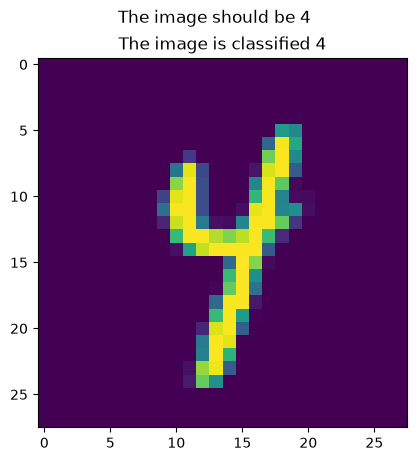

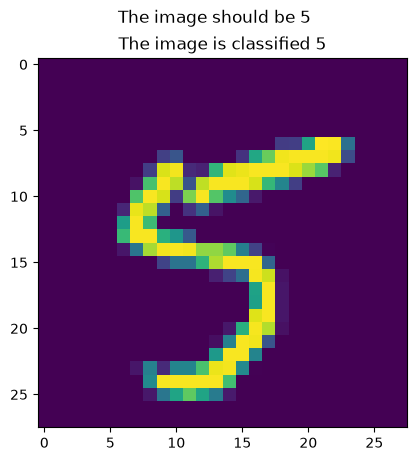

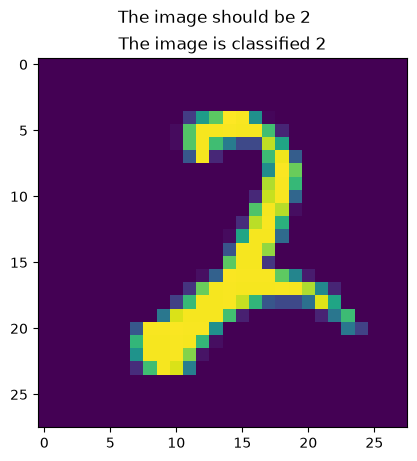

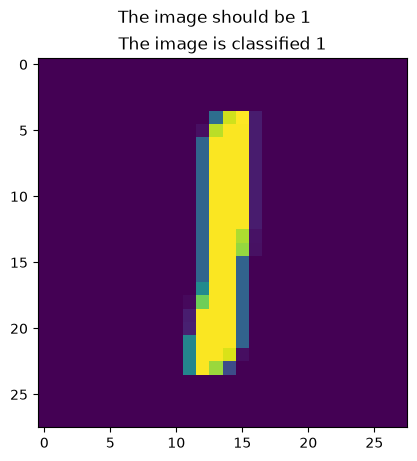

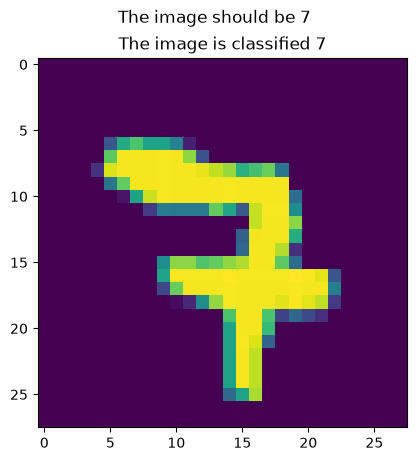

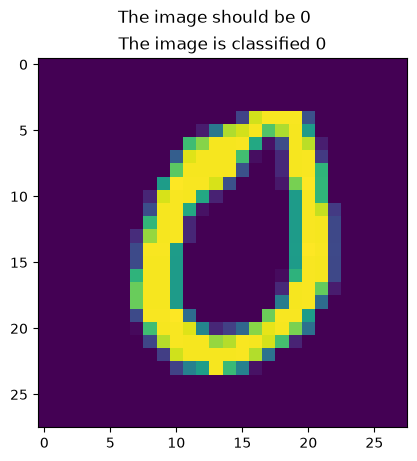

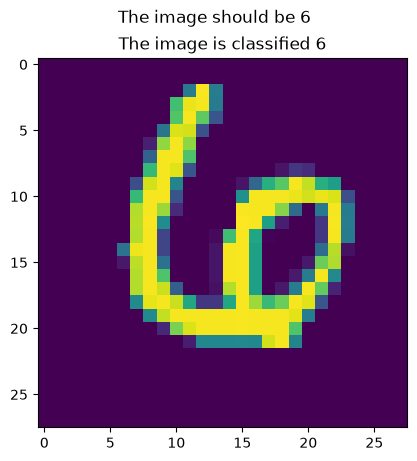

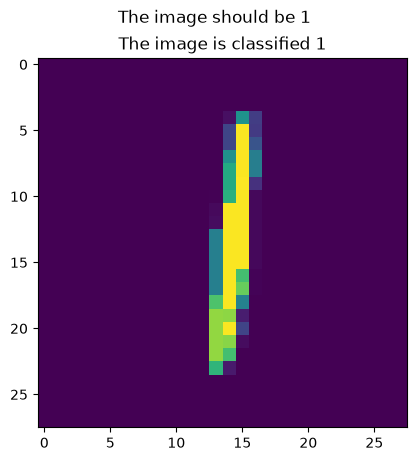

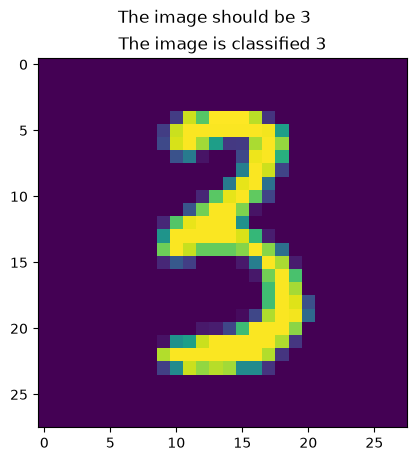

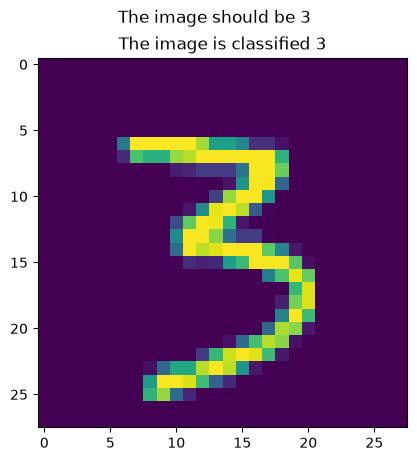

In [24]:
for k in np.random.choice( np.arange(5000) , size = 10 , replace=False):
    x_plot = X_test[:,k].reshape(28,-1)
    plt.imshow(x_plot)
    plt.suptitle(f'The image should be { y_test[k]}')
    plt.title(f'The image is classified { y_test_pred[k] }')
    plt.show()